In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
# Load the dataset
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
### Part 1: Understanding Product Categories
#**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?
#1. **Frequency Tables**:
#    - Generate a frequency table for the product `category`.
#    - Which are the top 5 most listed product categories?


frequency_table = df['category'].value_counts()
frequency_table

top_5_categories = frequency_table.head(5)
top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

/var/folders/mg/wjsd2dzj6zgdzk_gsdz19rdc0000gn/T/ipykernel_99407/3075328914.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_5_categories.index, y=top_5_categories.values, palette="Set3");


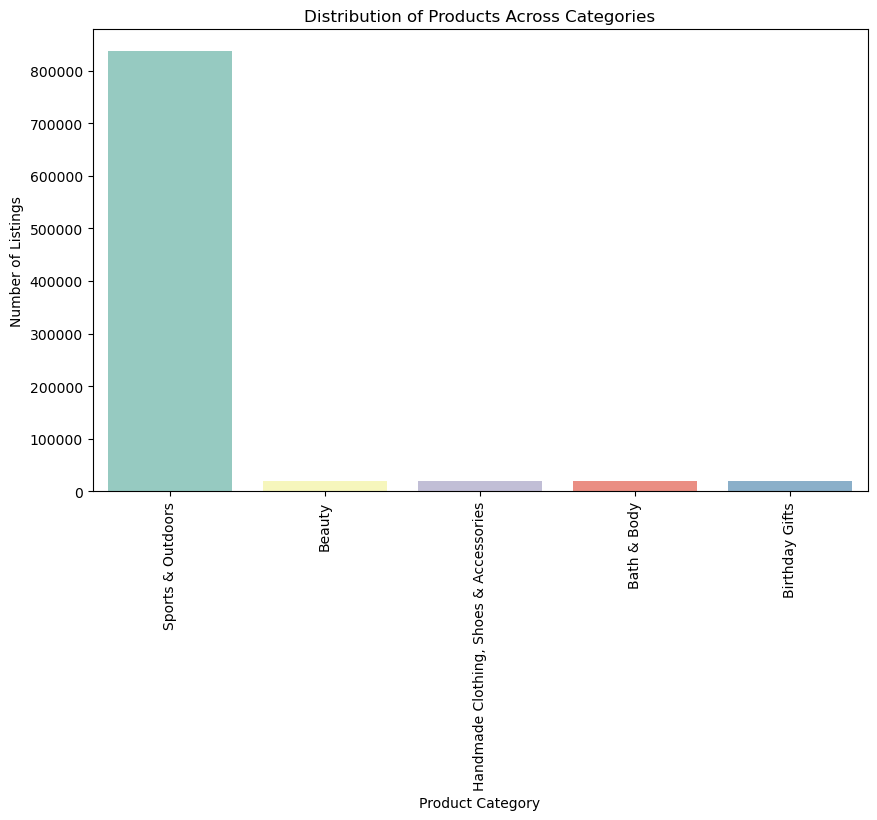

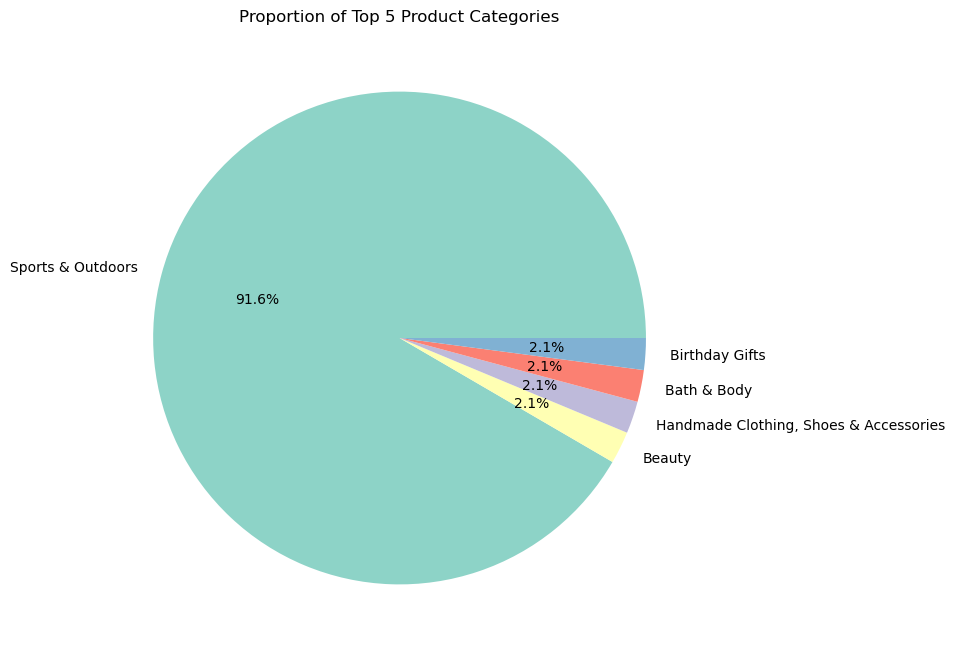

In [5]:
#2. **Visualizations**:
#    - Display the distribution of products across different categories using a bar chart. 
#       *If you face problems understanding the chart, do it for a subset of top categories.*
#    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

# Plotting a bar chart using the values from the top5 categories
plt.figure(figsize=(10,6))
sns.barplot(x=top_5_categories.index, y=top_5_categories.values, palette="Set3");
plt.xticks(rotation=90)
plt.title('Distribution of Products Across Categories')
plt.xlabel('Product Category')
plt.ylabel('Number of Listings')
plt.show()

#pie chart for the top 5 categories
plt.figure(figsize=(8,8))
plt.pie(top_5_categories.values, labels=top_5_categories.index, autopct='%1.1f%%', colors=sns.color_palette("Set3"))
plt.title('Proportion of Top 5 Product Categories')
plt.show()


#Sports & Outdoors appears to dominate the listings among the top 5 categories.

In [ ]:
### Part 2: Delving into Product Pricing
#**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?
#1. **Measures of Centrality**:
#    - Calculate the mean, median, and mode for the `price` of products.
#    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

df['price'].dtypes

print(df['price'].mean())
print(df['price'].median())
print(df['price'].mode())

#This suggests a right-skewed distribution (many low-priced items, few very expensive ones).

89.24380943923663
19.09
0    9.99
Name: price, dtype: float64


In [10]:

print(df['price'].std())
print(df['price'].var())
print(df['price'].max() - df['price'].min())



345.6088617535223
119445.4853225653
100000.0


<Axes: xlabel='price'>

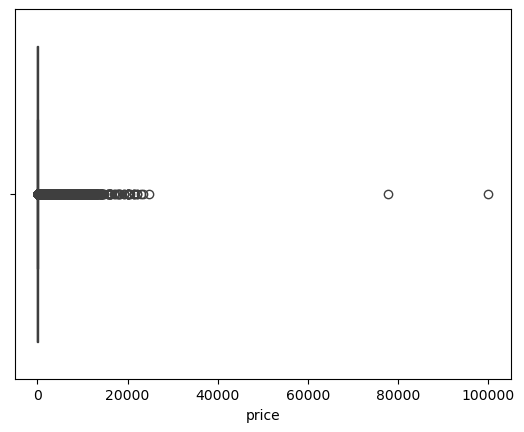

In [12]:
sns.boxplot(x=df['price'])

In [13]:

bins = [0, 10, 20, 50, 100, 200, 500]
labels = ['0-10', '10-20', '20-50', '50-100', '100-200', '200-500']
df['price_range'] = pd.cut(df['price'], bins=bins, labels=labels)
print(df['price_range'].value_counts())


price_range
10-20      650324
0-10       633399
20-50      594042
50-100     238612
100-200    133238
200-500    106511
Name: count, dtype: int64


Total rows: 2443651
Non-null ratings: 2443651

=== Centrality ===
Mean: 2.15
Median: 0.0
Mode: [0.0]

=== Dispersion ===
Standard Deviation: 2.195
Variance: 4.817
Q1: 0.0 | Q3: 4.4 | IQR: 4.4

=== Shape of Distribution ===
Skewness: 0.081
Kurtosis: -1.926


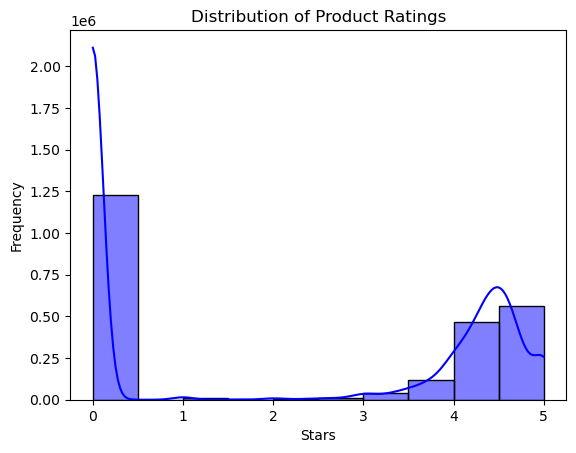


=== Interpretation ===
- Average rating is 2.15.
- Median rating is 0.0.
- Most common rating(s): [0.0].
- Ratings are slightly skewed to the right (more low ratings).


In [ ]:

# --- Part 3: Unpacking Product Ratings ---
# We will use the 'stars' column for ratings.

import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis  # For skewness and kurtosis

# 1) Convert 'stars' to numeric (in case there are strings)
df['stars'] = pd.to_numeric(df['stars'], errors='coerce')

# Check how many ratings we have
print("Total rows:", len(df))
print("Non-null ratings:", df['stars'].notna().sum())

# 2) Measures of Centrality
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()  # Mode can have multiple values

print("\n=== Centrality ===")
print("Mean:", round(mean_rating, 2))
print("Median:", round(median_rating, 2))x
print("Mode:", mode_rating.tolist())  # Convert to list for easy reading

# 3) Measures of Dispersion
std_rating = df['stars'].std()
var_rating = df['stars'].var()
q1 = df['stars'].quantile(0.25)
q3 = df['stars'].quantile(0.75)
iqr = q3 - q1

print("\n=== Dispersion ===")
print("Standard Deviation:", round(std_rating, 3))
print("Variance:", round(var_rating, 3))
print("Q1:", round(q1, 2), "| Q3:", round(q3, 2), "| IQR:", round(iqr, 2))

# 4) Shape of the Distribution
skewness = skew(df['stars'].dropna())
kurt = kurtosis(df['stars'].dropna())

print("\n=== Shape of Distribution ===")
print("Skewness:", round(skewness, 3))
print("Kurtosis:", round(kurt, 3))

# 5) Visualisation: Histogram
sns.histplot(df['stars'], bins=10, kde=True, color="blue")
plt.title("Distribution of Product Ratings")
plt.xlabel("Stars")
plt.ylabel("Frequency")
plt.show()

# 6) Simple Interpretation
print("\n=== Interpretation ===")
print(f"- Average rating is {round(mean_rating, 2)}.")
print(f"- Median rating is {round(median_rating, 2)}.")
print(f"- Most common rating(s): {mode_rating.tolist()}.")
if skewness > 0:
    print("- Ratings are slightly skewed to the right (more low ratings).")
elif skewness < 0:
    print("- Ratings are slightly skewed to the left (more high ratings).")
else:
    print("- Ratings are roughly symmetric.")
